# Google Quick, Draw! - ROC-AUC and Single-Layer Perceptron

**What is done here**
1. Macro one-vs-rest ROC-AUC and per-class ROC curves for the tuned CNN (saved model from notebook 05), on the **validation** set.
2. A single-layer perceptron (one Dense softmax layer, no hidden layer) on the 784 flattened pixels, with two learning rates chosen on validation. This sits below the MLP and CNN and shows what a purely linear neural model achieves.

**Rules followed.** Validation set only. The test set is not loaded. Seed 42.


## 1. Setup

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support, roc_auc_score,
                             roc_curve, auc)
from sklearn.preprocessing import label_binarize

SEED = 42
keras.utils.set_random_seed(SEED)

root = Path("..")
data_path   = root / "data" / "quickdraw" / "quickdraw_8class_processed.npz"
results_dir = root / "results"
figures_dir = root / "figures"
results_dir.mkdir(exist_ok=True)
figures_dir.mkdir(exist_ok=True)
print("TensorFlow", tf.__version__)

TensorFlow 2.21.0


## 2. Load training and validation data

In [2]:
data = np.load(data_path, allow_pickle=True)
X_train, y_train = data["X_train"], data["y_train"]          # (19200, 28, 28, 1)
X_val,   y_val   = data["X_val"],   data["y_val"]            # (2400, 28, 28, 1); test set not loaded
categories = [str(c) for c in data["categories"]]
n_classes = len(categories)
y_val_bin = label_binarize(y_val, classes=list(range(n_classes)))   # one 0/1 column per class
print(X_train.shape, X_val.shape, categories)

(19200, 28, 28, 1) (2400, 28, 28, 1) ['airplane', 'apple', 'bicycle', 'cat', 'fish', 'guitar', 'house', 'tree']


## 3. ROC-AUC for the tuned CNN (validation)

For each class, the CNN's predicted probability for that class is used as a score, and "this class" versus "all other classes" is the truth. The ROC curve plots true-positive rate against false-positive rate as the decision threshold moves. The area under it (AUC) is 1.0 for a perfect ranking and 0.5 for random guessing. The macro AUC is the plain average over the 8 classes.

Accuracy only determines if the highest probability class is the correct class . So it gives one number for one way of making decisions . Instead a ROC curve uses the predicted probabilities. It plots the true positive rate against the false positive rate for each class (one-vs-rest) at varying threshold. This shows how well the model ranks drawings of that class higher than drawings of other classes. Something accuracy can’t show. This is expressed by the area under the curve (AUC) where 1.0 is perfect ranking and 0.5 is random guessing. Our CNN achieves a macro ROC-AUC of 0.9978. Even cat (0.9957) and airplane (0.9951) are well separated, classes it most often misclassifies. It mostly misclassifies a few hard drawings near the decision boundary, not because it is confused about the class as a whole.

CNN validation accuracy 0.9554 | macro one-vs-rest ROC-AUC 0.9978


,class,roc_auc
0,airplane,0.9951
1,apple,0.9988
2,bicycle,0.9981
3,cat,0.9957
4,fish,0.9976
5,guitar,0.9990
6,house,0.9987
7,tree,0.9996


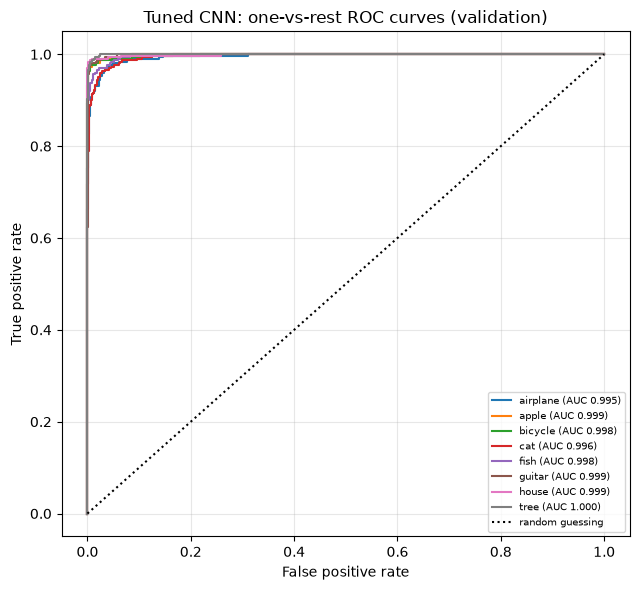

In [3]:
cnn = keras.models.load_model(results_dir / "quickdraw_cnn_best.keras")
val_probs = cnn.predict(X_val, verbose=0)                    # (2400, 8) class probabilities
val_pred = val_probs.argmax(axis=1)

macro_auc = roc_auc_score(y_val_bin, val_probs, average="macro")
per_class_auc = {categories[c]: roc_auc_score(y_val_bin[:, c], val_probs[:, c]) for c in range(n_classes)}
print(f"CNN validation accuracy {accuracy_score(y_val, val_pred):.4f} | macro one-vs-rest ROC-AUC {macro_auc:.4f}")

auc_table = pd.DataFrame({"class": list(per_class_auc.keys()), "roc_auc": np.round(list(per_class_auc.values()), 4)})
auc_table.to_csv(results_dir / "quickdraw_cnn_val_auc_per_class.csv", index=False)
display(auc_table)

fig, ax = plt.subplots(figsize=(6.5, 6))
for c in range(n_classes):
    fpr, tpr, _ = roc_curve(y_val_bin[:, c], val_probs[:, c])
    ax.plot(fpr, tpr, label=f"{categories[c]} (AUC {auc(fpr, tpr):.3f})")
ax.plot([0, 1], [0, 1], "k:", label="random guessing")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate")
ax.set_title("Tuned CNN: one-vs-rest ROC curves (validation)")
ax.legend(fontsize=7, loc="lower right"); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_cnn_roc_val.png", dpi=150)
plt.show()

## 4. Single-layer perceptron on flattened pixels

One Dense layer with 8 softmax outputs sits directly on the 784 pixels: no hidden layer, no convolution. It is trained with early stopping on validation loss. Two learning rates are compared and the better one is chosen on validation macro F1.

This model is one Dense layer with 8 softmax outputs connected directly to the 784 pixels, so it has only 6,280 parameters (784 × 8 weights plus 8 biases). With softmax and cross-entropy loss, it is basically the same model as multinomial logistic regression. Both are linear, so each class gets a score that is a weighted sum of the pixels. The only real differences are how they are trained. Logistic regression in scikit-learn uses the lbfgs solver with an L2 penalty (C=0.1), while this model uses Adam in mini-batches and relies on early stopping instead of a penalty to avoid overfitting. Because of this, the results are very close: 0.8326 macro F1 here against 0.8392 for the logistic regression. The MLP is different because it adds hidden layers with ReLU (256 and 128 units), so it can learn non-linear combinations of pixels that a single linear layer can’t. That is why the MLP does much better (0.9035).

In [4]:
Xf_train = X_train.reshape(len(X_train), -1)
Xf_val   = X_val.reshape(len(X_val), -1)

def build_perceptron(learning_rate):
    model = keras.Sequential([keras.Input(shape=(784,)), layers.Dense(n_classes, activation="softmax")])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    return model

rows, histories = [], {}
for lr in (1e-3, 1e-2):
    keras.utils.set_random_seed(SEED)
    model = build_perceptron(lr)
    stop = keras.callbacks.EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True)
    start = time.perf_counter()
    hist = model.fit(Xf_train, y_train, validation_data=(Xf_val, y_val), epochs=50,
                     batch_size=64, callbacks=[stop], verbose=0)
    seconds = time.perf_counter() - start
    probs = model.predict(Xf_val, verbose=0)
    pred = probs.argmax(axis=1)
    p, r, f1, _ = precision_recall_fscore_support(y_val, pred, average="macro", zero_division=0)
    h = hist.history
    best_epoch = int(np.argmin(h["val_loss"])) + 1
    rows.append({"learning_rate": lr, "params": model.count_params(), "epochs_run": len(h["loss"]),
                 "best_epoch": best_epoch, "train_acc_at_best": h["accuracy"][best_epoch - 1],
                 "val_accuracy": accuracy_score(y_val, pred), "val_macro_precision": p,
                 "val_macro_recall": r, "val_macro_f1": f1,
                 "val_macro_auc": roc_auc_score(y_val_bin, probs, average="macro"), "train_time_s": seconds})
    histories[lr] = h
    print(f"lr {lr}: val acc {rows[-1]['val_accuracy']:.4f}, macro F1 {f1:.4f}, AUC {rows[-1]['val_macro_auc']:.4f}, best epoch {best_epoch}")

perc = pd.DataFrame(rows).round(4)
perc.to_csv(results_dir / "quickdraw_perceptron_val.csv", index=False)
try:
    display(perc.style.highlight_max(subset=["val_macro_f1"], props="font-weight: bold; background-color: #d6f5d6"))
except Exception:
    display(perc)

lr 0.001: val acc 0.8333, macro F1 0.8326, AUC 0.9729, best epoch 6
lr 0.01: val acc 0.8104, macro F1 0.8087, AUC 0.9693, best epoch 1


,learning_rate,params,epochs_run,best_epoch,train_acc_at_best,val_accuracy,val_macro_precision,val_macro_recall,val_macro_f1,val_macro_auc,train_time_s
0,0.001000,6280,9,6,0.839600,0.833300,0.833000,0.833300,0.832600,0.972900,3.422800
1,0.010000,6280,4,1,0.793400,0.810400,0.814900,0.810400,0.808700,0.969300,1.778700


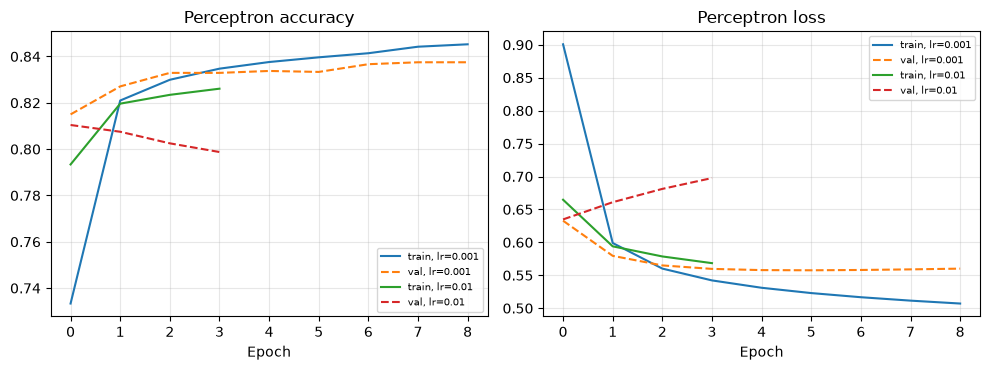

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8))
for lr, h in histories.items():
    axes[0].plot(h["accuracy"], label=f"train, lr={lr}")
    axes[0].plot(h["val_accuracy"], "--", label=f"val, lr={lr}")
    axes[1].plot(h["loss"], label=f"train, lr={lr}")
    axes[1].plot(h["val_loss"], "--", label=f"val, lr={lr}")
axes[0].set_title("Perceptron accuracy"); axes[1].set_title("Perceptron loss")
for ax in axes:
    ax.set_xlabel("Epoch"); ax.grid(alpha=0.3); ax.legend(fontsize=7)
plt.tight_layout()
plt.savefig(figures_dir / "quickdraw_perceptron_curves.png", dpi=150)
plt.show()

## 5. Findings

1. Tree has the highest CNN AUC (0.9996) and airplane the lowest (0.9951), with cat close behind (0.9957). This mostly matches the test confusion matrix in notebook 06, where airplane and cat were also the weakest classes (F1 0.9073 and 0.9082) and tree and house were among the strongest. Guitar is the exception: it has a high AUC (0.9990) but test recall of only 0.8967. AUC measures ranking across all thresholds, while the confusion matrix only counts the top prediction, and the two were measured on different sets (validation vs test).

2. The perceptron (0.8333 accuracy, 0.8326 macro F1) performs almost the same as logistic regression (0.8392), as expected since both are linear models on the 784 pixels. It beats the decision tree (0.7349) but is behind k-NN (0.8930), Random Forest (0.8907), the MLP (0.9035) and the CNN (0.9556).

3. The CNN is about 12 points ahead of the perceptron. The MLP's hidden layers close about 7 points of that gap, and the CNN adds another 5 with almost the same number of parameters as the MLP (241,288 vs about 235,000). Since the main difference is that the CNN keeps the 2D layout and looks at neighbouring pixels together, this shows that much of the useful information in the drawings comes from spatial structure: how strokes connect into shapes.